## Name: Harsh Sambare
## Class: C-C1
## Roll No: 8
## ML LAB 9

# Customer Segmentation Using K-Means and Hierarchical Clustering

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")

df = pd.read_csv("Wholesale customers data.csv")
df.head()


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [2]:
print("Dataset shape:", df.shape)
print("\nColumn data types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
display(df.describe().round(2))


Dataset shape: (440, 8)

Column data types:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

Missing values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate rows: 0

Summary statistics:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00,440.00,440.00
mean,1.32,2.54,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,0.47,0.77,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,1.00,1.00,3.00,55.00,3.00,25.00,3.00,3.00
25%,1.00,2.00,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,1.00,3.00,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,2.00,3.00,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,2.00,3.00,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00


In [3]:
df = df.drop_duplicates().copy()
X = df.select_dtypes(include=[np.number]).copy()
X = X.fillna(X.median())

print("Data used for clustering:", X.shape)
display(X.head())


Data used for clustering: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


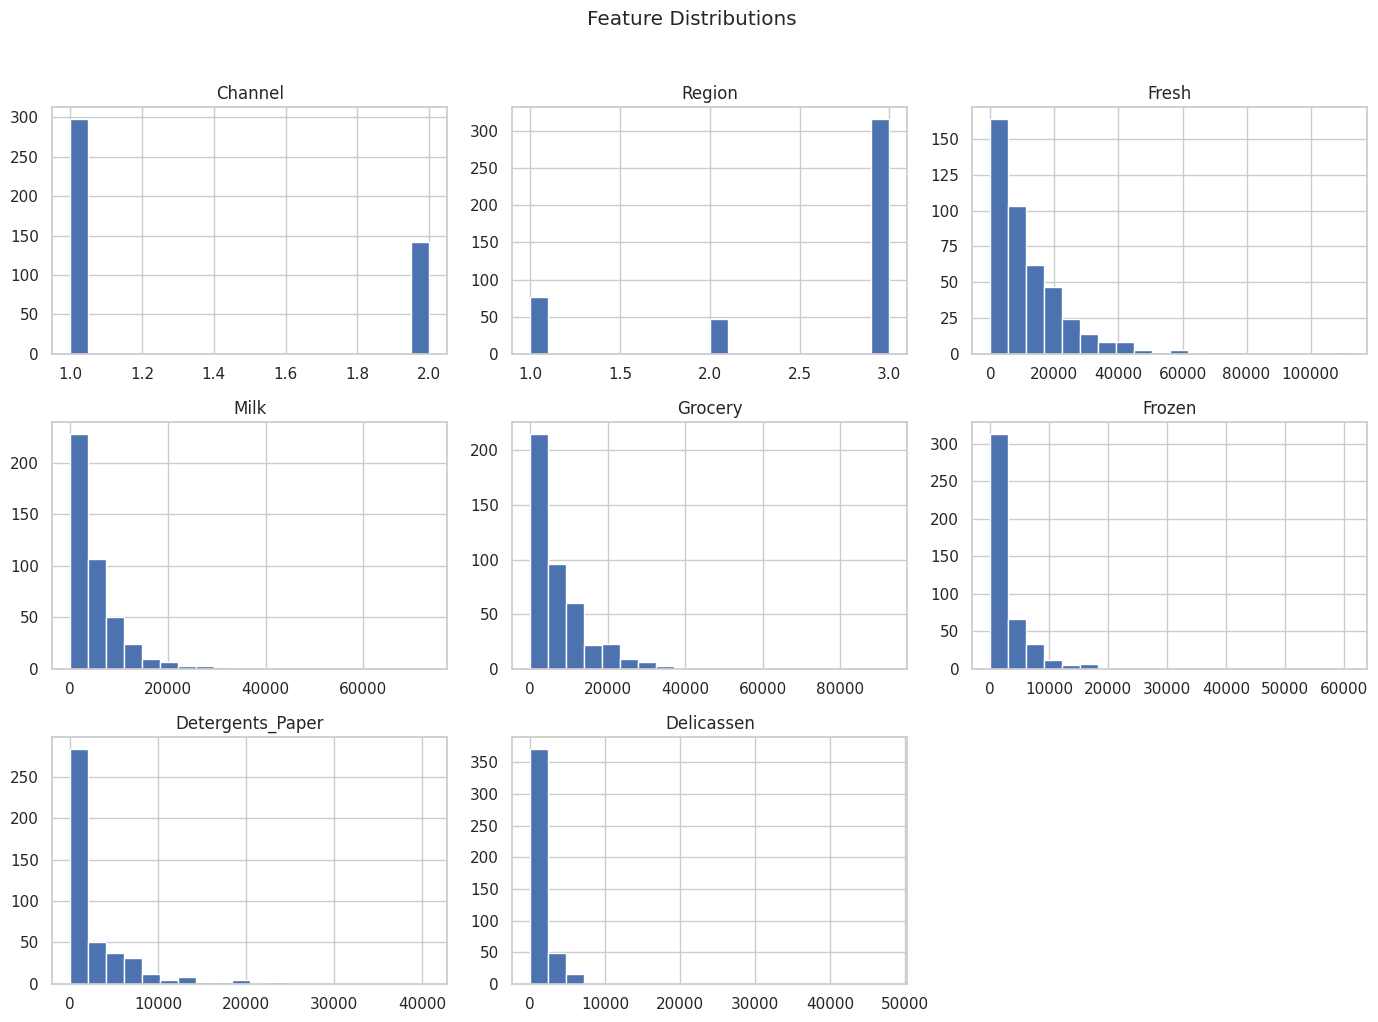

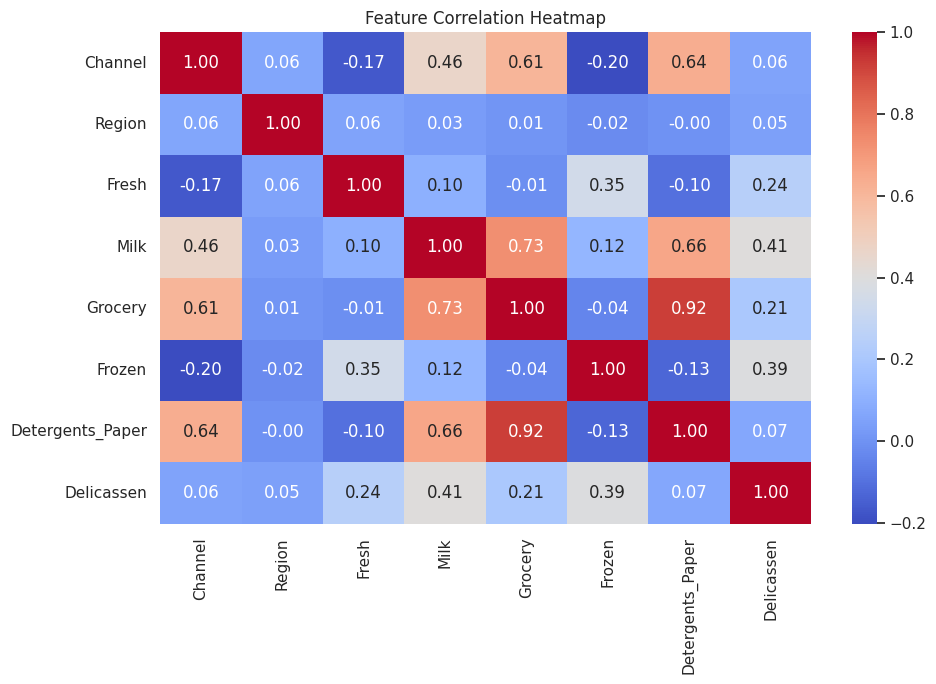

In [4]:
X.hist(figsize=(14, 10), bins=20)
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
display(X_scaled_df.head())
print("\nScaled feature means:")
print(X_scaled_df.mean().round(3))
print("\nScaled feature standard deviations:")
print(X_scaled_df.std(ddof=0).round(3))


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.448652,0.590668,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,1.448652,0.590668,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,1.448652,0.590668,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,-0.690297,0.590668,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,1.448652,0.590668,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347



Scaled feature means:
Channel             0.0
Region              0.0
Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64

Scaled feature standard deviations:
Channel             1.0
Region              1.0
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


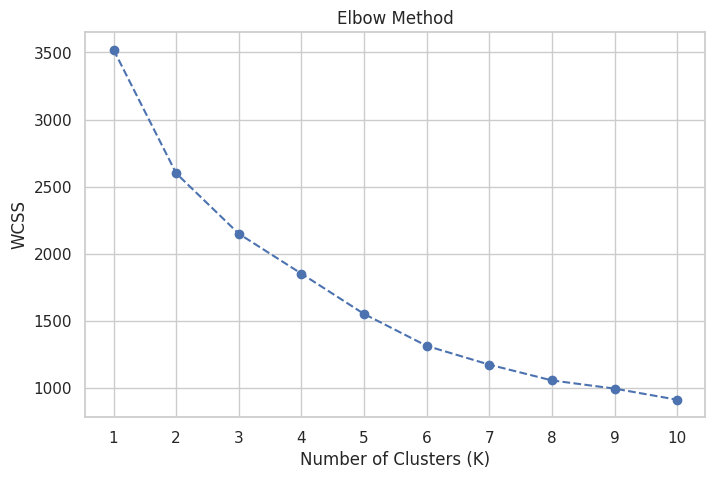

In [6]:
wcss = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker="o", linestyle="--")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [7]:
silhouette_values = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    silhouette_values.append(silhouette_score(X_scaled, labels))

silhouette_table = pd.DataFrame({
    "Number of Clusters": range(2, 11),
    "Silhouette Score": silhouette_values
})
display(silhouette_table.round(3))


,Number of Clusters,Silhouette Score
0,2,0.373
1,3,0.357
2,4,0.348
3,5,0.353
4,6,0.353
5,7,0.364
6,8,0.374
7,9,0.308
8,10,0.331


In [8]:
suggested_k = 3
print("Selected number of clusters:", suggested_k)


Selected number of clusters: 3


In [9]:
kmeans = KMeans(n_clusters=suggested_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

print("K-Means clustering completed.")
print("\nCustomers in each K-Means cluster:")
print(df_kmeans["KMeans_Cluster"].value_counts().sort_index())
display(df_kmeans.head())


K-Means clustering completed.

Customers in each K-Means cluster:
KMeans_Cluster
0    130
1    297
2     13
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,KMeans_Cluster
0,2,3,12669,9656,7561,214,2674,1338,0
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,0
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,0


In [10]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=suggested_k,
    linkage="ward"
)
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed.")
print("\nCustomers in each Hierarchical cluster:")
print(df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index())
display(df_hierarchical.head())


Hierarchical clustering completed.

Customers in each Hierarchical cluster:
Hierarchical_Cluster
0      6
1    298
2    136
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Hierarchical_Cluster
0,2,3,12669,9656,7561,214,2674,1338,2
1,2,3,7057,9810,9568,1762,3293,1776,2
2,2,3,6353,8808,7684,2405,3516,7844,2
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,2


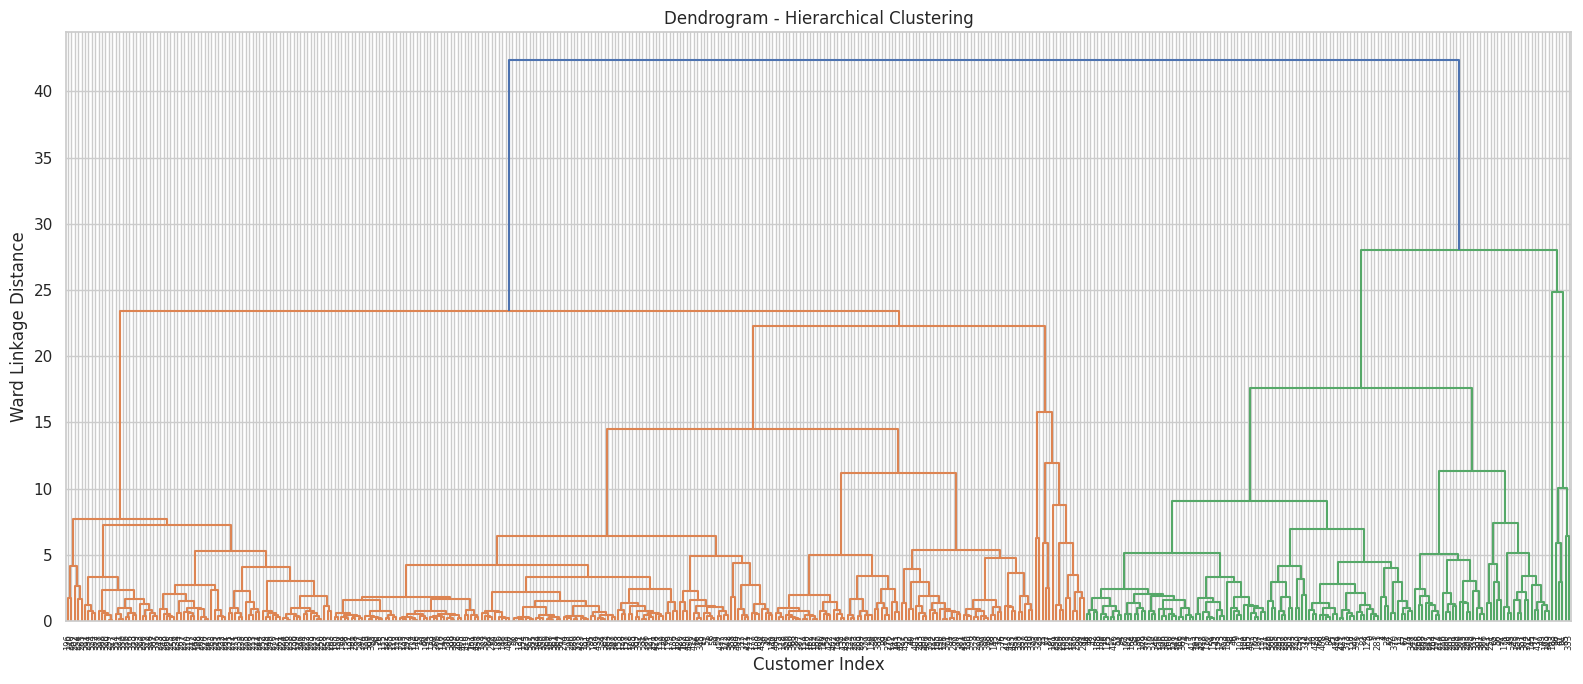

In [11]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(16, 7))
dendrogram(Z, leaf_rotation=90, leaf_font_size=6)
plt.title("Dendrogram - Hierarchical Clustering")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()


In [12]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans_Cluster": kmeans_labels.astype(str),
    "Hierarchical_Cluster": hierarchical_labels.astype(str)
})

print("Variance explained by the two PCA components:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")


Variance explained by the two PCA components: 61.12 %


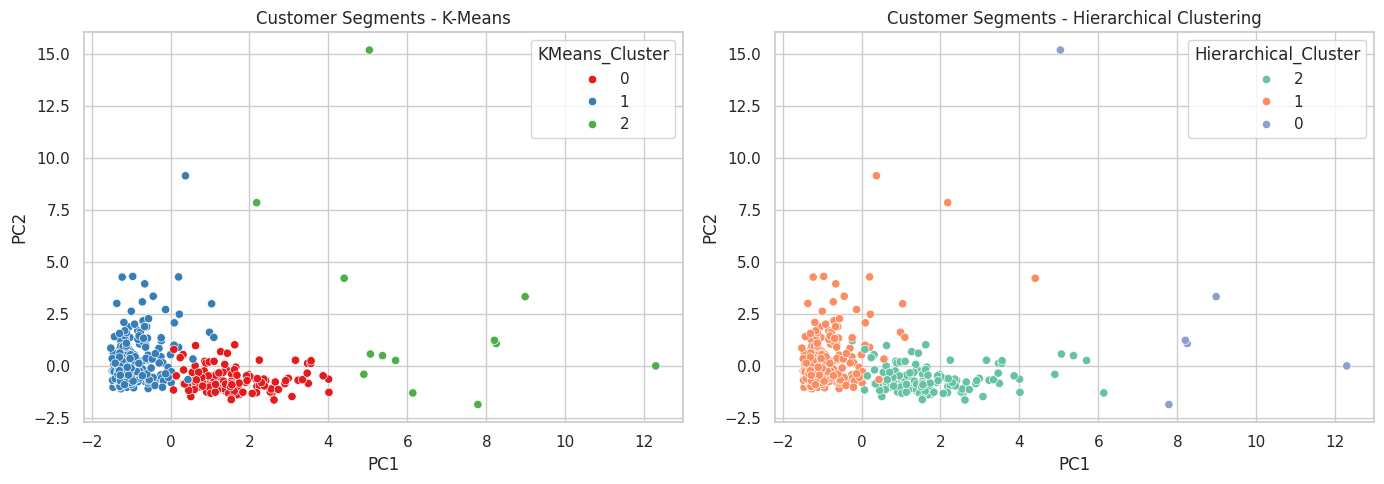

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="KMeans_Cluster",
                palette="Set1", ax=axes[0])
axes[0].set_title("Customer Segments - K-Means")

sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Hierarchical_Cluster",
                palette="Set2", ax=axes[1])
axes[1].set_title("Customer Segments - Hierarchical Clustering")

plt.tight_layout()
plt.show()


In [14]:
comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Number of Clusters": len(np.unique(kmeans_labels)),
        "Silhouette Score": silhouette_score(X_scaled, kmeans_labels)
    },
    {
        "Algorithm": "Hierarchical Clustering",
        "Number of Clusters": len(np.unique(hierarchical_labels)),
        "Silhouette Score": silhouette_score(X_scaled, hierarchical_labels)
    }
])

display(comparison.round(3))


,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,3,0.357
1,Hierarchical Clustering,3,0.360


In [15]:
features = X.columns.tolist()
df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

cluster_profiles = df_kmeans.groupby("KMeans_Cluster")[features].mean().round(2)
cluster_sizes = df_kmeans["KMeans_Cluster"].value_counts().sort_index()

print("Average feature values for each K-Means customer segment:")
display(cluster_profiles)
print("\nNumber of customers in each segment:")
display(cluster_sizes.to_frame("Customer Count"))


Average feature values for each K-Means customer segment:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,,,
0,2.00,2.62,8165.92,8748.52,13905.49,1441.63,5991.15,1535.01
1,1.00,2.51,13075.90,3218.74,3855.70,3620.40,776.88,1242.25
2,1.85,2.62,25770.77,35160.38,41977.38,6844.54,19867.38,7880.31



Number of customers in each segment:


,Customer Count
KMeans_Cluster,
0,130
1,297
2,13


In [16]:
for cluster_id, row in cluster_profiles.iterrows():
    top_features = row.sort_values(ascending=False).head(3).index.tolist()
    print(f"Cluster {cluster_id} ({cluster_sizes.loc[cluster_id]} customers): "
          f"highest average spending is in {', '.join(top_features)}.")


Cluster 0 (130 customers): highest average spending is in Grocery, Milk, Fresh.
Cluster 1 (297 customers): highest average spending is in Fresh, Grocery, Frozen.
Cluster 2 (13 customers): highest average spending is in Grocery, Milk, Fresh.
